In [2]:
import utils

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
import pandas as pd

In [8]:
utils.descarga("https://ignaciorlando.github.io/datasets/data-science/ObesityDataSet_raw_and_data_sinthetic.csv", "ObesityDataSet_raw_and_data_sinthetic.csv", 1)

In [5]:
df = pd.read_csv("ObesityDataSet_raw_and_data_sinthetic.csv")

<h3>Estandarizacion

In [21]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df.select_dtypes(include="number"))

<h3>Inciso a

Aplicar PCA únicamente sobre las variables cuantitativas, y graficar las dos
principales componentes en un scatter plot.

In [6]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

In [22]:
#nos quedamos solo con las columnas numericas
df_PCA = df.select_dtypes(include="number")

In [23]:
#objeto PCA que mapea a 2 dimensiones con normalizacion porque PCA es sensible a la escala de los datos
#estandarizando llevamos a todo de 0 a 1 permitiendo que todas las variables contribuyan de manera equitativa a la varianza total
pca = PCA(n_components=2, whiten=False)

In [24]:
#le pedimos al objeto que se ajuste utilizando los datos (fit) y que además
# transforme los datos, para ya reducir a dos dimensiones
principalComponents = pca.fit_transform(df_scaled)

In [25]:
print('Antes de PCA: {}'.format(df_PCA.shape))
print('Después de PCA: {}'.format(principalComponents.shape))

Antes de PCA: (2111, 8)
Después de PCA: (2111, 2)


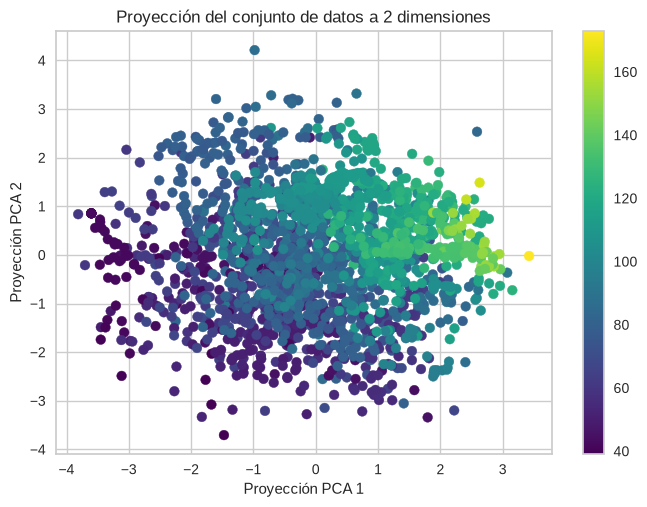

In [26]:
#graficamos cada punto mediante un scatter plot, donde cada punto es un registro del dataset
plt.scatter(principalComponents[:,0], principalComponents[:,1], c=df["Weight"], cmap='viridis')
plt.grid(True)
plt.xlabel('Proyección PCA 1')
plt.ylabel('Proyección PCA 2')
plt.title('Proyección del conjunto de datos a 2 dimensiones')
plt.colorbar()
plt.show()

Podemos ver que el peso tienen pueden representar una relacion entre las variables del dataset ya que existe una evolucion del mismo peso de izquierda a derecha

<h3>Inciso b

¿Cuál es el total de la varianza explicada? ¿Y cuál es el ratio de varianza
explicada por cada una de las componentes? ¿alcanzan las dos
componentes para obtener una imagen representativa?

In [27]:
pca.explained_variance_ratio_

array([0.22648604, 0.18657893])

In [28]:
print(pca.explained_variance_ratio_[0]+pca.explained_variance_ratio_[1])

0.4130649752725934


Podemos ver claramente que el total de la varianza explicada es de 0.9968% donde la primer componente aporta 0.9439% y la segunda componente 0.0529%

Alcanzan ambas componentes, ya que representan un porcentaje muy alto de la varianza total de la informacion

<h3>Inciso c

In [29]:
df_nn = df.select_dtypes(exclude="number")

In [30]:
df_nn.columns

Index(['Gender', 'CALC', 'FAVC', 'SCC', 'SMOKE',
       'family_history_with_overweight', 'CAEC', 'MTRANS', 'NObeyesdad'],
      dtype='str')

In [31]:
df_nn.value_counts()

Gender  CALC       FAVC  SCC  SMOKE  family_history_with_overweight  CAEC        MTRANS                 NObeyesdad         
Female  Sometimes  yes   no   no     yes                             Sometimes   Public_Transportation  Obesity_Type_III       321
Male    Sometimes  yes   no   no     yes                             Sometimes   Public_Transportation  Obesity_Type_II        130
                                                                                                        Overweight_Level_II     76
        no         yes   no   no     yes                             Sometimes   Public_Transportation  Obesity_Type_I          75
        Sometimes  yes   no   no     yes                             Sometimes   Automobile             Obesity_Type_II         74
                                                                                                                              ... 
        no         yes   yes  no     yes                             Always      Motorbike

Generar diferentes versiones de ese scatter plot, coloreando en gráficas
separadas distintos valores de variable categórica. ¿Qué características se
observan en los grupos? ¿Es posible separar grupos en función de esas
observaciones? Justificar.

<h4>Por sexo

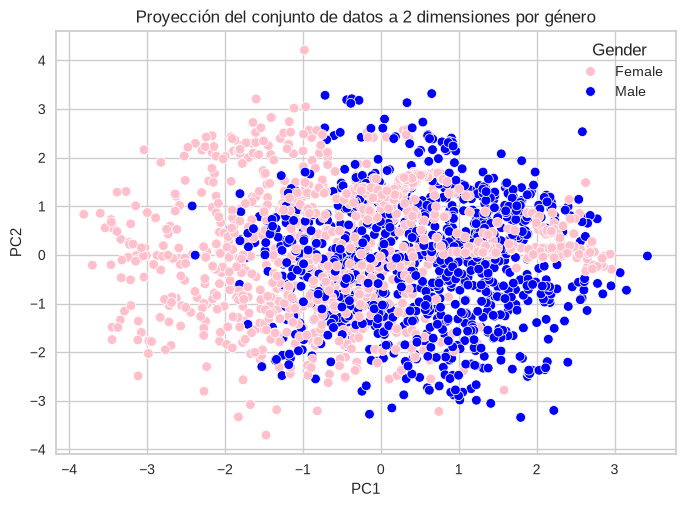

In [32]:
df_pca = pd.DataFrame({
    "PC1": principalComponents[:, 0],
    "PC2": principalComponents[:, 1],
    "Gender": df["Gender"].values
})

sns.scatterplot(
    data=df_pca,
    x="PC1",
    y="PC2",
    hue="Gender",
    palette=["pink", "blue"]
)
plt.title("Proyección del conjunto de datos a 2 dimensiones por género")
plt.show()

Podemos ver que las personas de sexo masculino poseen una menor varianza en la primera componente (Peso)

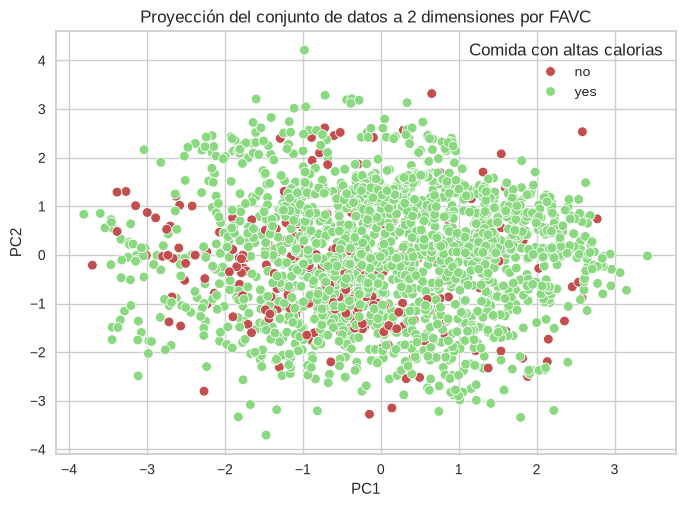

In [33]:
df_pca = pd.DataFrame({
    "PC1": principalComponents[:, 0],
    "PC2": principalComponents[:, 1],
    "Comida con altas calorias": df["FAVC"].values
})

sns.scatterplot(
    data=df_pca,
    x="PC1",
    y="PC2",
    hue="Comida con altas calorias",
    palette=["#C34E4E", "#8AD981"]
)
plt.title("Proyección del conjunto de datos a 2 dimensiones por FAVC")
plt.show()

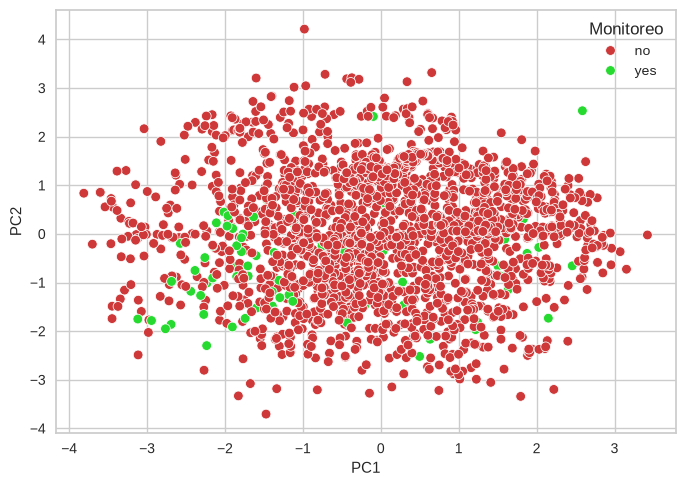

In [34]:
df_pca = pd.DataFrame({
    "PC1": principalComponents[:, 0],
    "PC2": principalComponents[:, 1],
    "Monitoreo": df["SCC"].values
})

sns.scatterplot(
    data=df_pca,
    x="PC1",
    y="PC2",
    hue="Monitoreo",
    palette=["#CE3838", "#27DA30"]
)

plt.show()

Podemos ver a priori que la variable dicotomica nos aporta ver como el grupo que si monitorea las calorias en las comidas se ubica en valores bajos de la primer y segunda componente

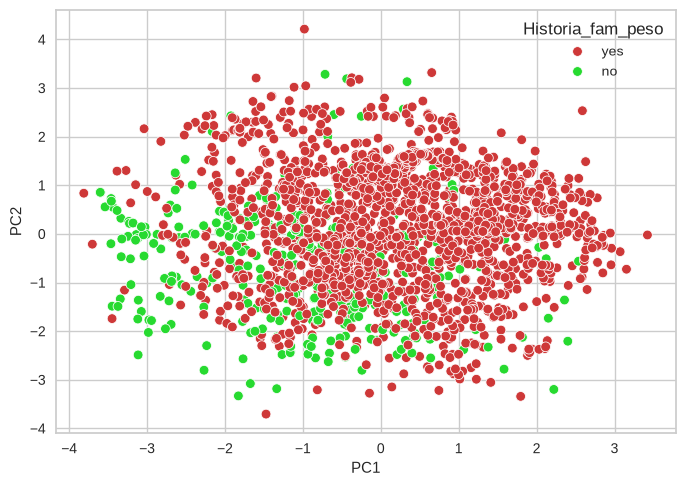

In [35]:
df_pca = pd.DataFrame({
    "PC1": principalComponents[:, 0],
    "PC2": principalComponents[:, 1],
    "Historia_fam_peso": df["family_history_with_overweight"].values
})

sns.scatterplot(
    data=df_pca,
    x="PC1",
    y="PC2",
    hue="Historia_fam_peso",
    palette=["#CE3838", "#27DA30"]
)

plt.show()

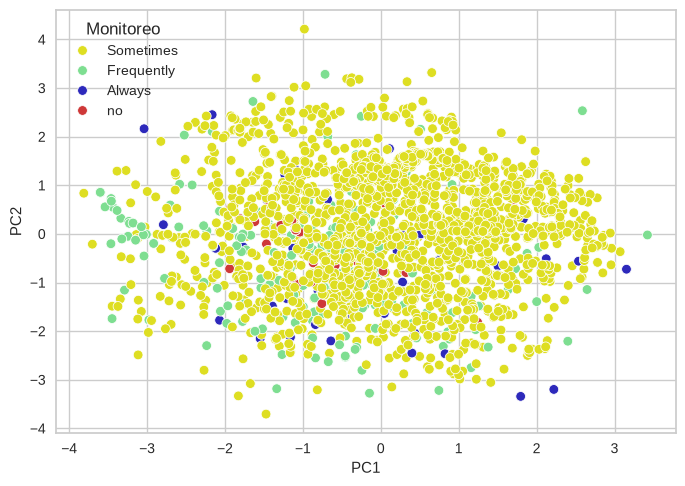

In [36]:
df_pca = pd.DataFrame({
    "PC1": principalComponents[:, 0],
    "PC2": principalComponents[:, 1],
    "Monitoreo": df["CAEC"].values
})

sns.scatterplot(
    data=df_pca,
    x="PC1",
    y="PC2",
    hue="Monitoreo",
    palette=["#DEDE22", "#7EDE91", "#2D29BB", "#CE3838"]
)

plt.show()

<h3>Inciso d

Representar las dos componentes principales en un biplot y analizar la
influencia de las diferentes variables en cada dimensión.

In [40]:
import pandas as pd

loadings = pd.DataFrame(
    viz.pca_components_.T,
    index=df_PCA.columns,
    columns=["PC1", "PC2"]
)

print(loadings.sort_values("PC1", ascending=False))

             PC1       PC2
Height  0.598077 -0.070295
Weight  0.503661  0.361779
CH2O    0.384655 -0.052993
NCP     0.333123 -0.127778
FAF     0.321236 -0.361647
FCVC    0.161968  0.260187
TUE     0.014639 -0.531014
Age     0.007592  0.603802


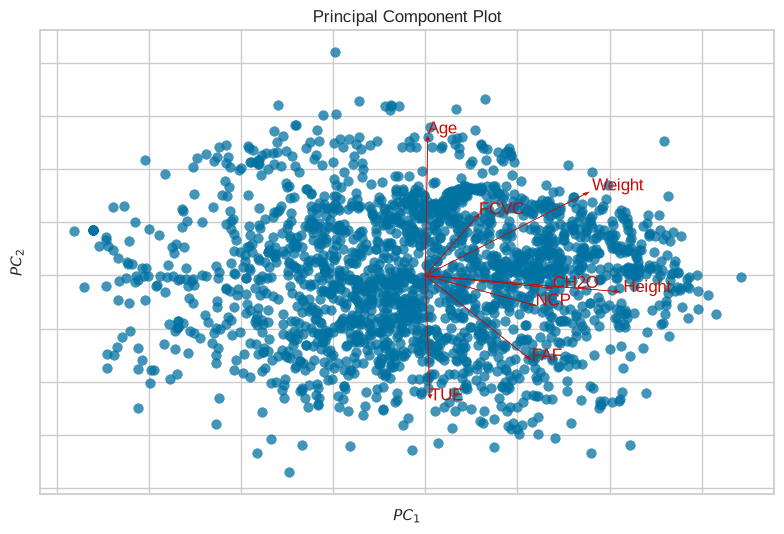

<Axes: title={'center': 'Principal Component Plot'}, xlabel='$PC_1$', ylabel='$PC_2$'>

In [39]:
from yellowbrick.features import PCA as PcaViz

# declaramos un objeto de la clase PcaViz:
viz = PcaViz(
    scale=True,          # le vamos a pedir que estandarice (si le pasáramos datos estandarizados esto va en false)
    proj_features=True,  # le pedimos que dibuje las proyecciones de la features originales
    projection=2,        # le pedimos dos proyecciones
)
# lo aplicamos sobre los datos originales
df_viz = df.select_dtypes(include="number")
viz.fit_transform(df_viz)
# y pedimos que se grafique
viz.show()

Podemos ver claramente que PC1 es representada en su totalidad por el peso y PC2 es representada en su totalidad por la altura

- Podemos ver que CH20 y Height tienen un angulo muy chiquito entre ellos y por consecuencia una correlacion alta. Esto tal vez no tiene un significado real pero si nos dice que tenemos redundancia entre ambas variables

- Podemos ver que el peso y la altura son los que representan la mayor varianza dentro de la componente 1 y la edad es la que representa la mayor varianza en la componente 2

- Ademas, vemos que FCVC, Weight, CH20, Height, NCP y FAF contribuyen al incremento de la componente 1. Por otro lado, Age, Weight y FCVC contribuyen al incremento de la componente 1 y el resto disminuye a la componente 2